# Grover's Search on the Grid: Finding a Clean Key Route

*Secure the Grid · Step 3 (network design) · follows notebook 2b*

Notebook 2b used Grover's search to find one secret key among N. Here the same circuit picks a **clean route** for a quantum key among N candidate routes on Chattanooga's real EPB / TVA grid. A route is clean when every fiber on it is a QKD fiber, in service, with measured QBER under the cutoff (11%, the Shor–Preskill limit).

The plan, in order:
1. Load the Chattanooga network.
2. Solve the routing problem classically (this is the real answer, and it is exact).
3. List N = 8 candidate routes (Yen's k shortest paths), with one tapped fiber so some are dirty.
4. Run Grover with M marked (clean) routes on Qiskit Aer, 200 shots, and check the pick classically.
5. The M = 0 case: no clean route, so the key falls back to ML-KEM.
6. What this does and does not show.

Everything runs locally on Qiskit Aer: no jobs, no credits.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

sim = AerSimulator(seed_simulator=2026)   # seeded so the saved outputs are reproducible
print("Setup OK: Qiskit Aer is ready (local, noise-free, free).")

Setup OK: Qiskit Aer is ready (local, noise-free, free).


## 1. Load Chattanooga

Real substations and power lines from OpenStreetMap. QKD runs on the 161 kV / 230 kV / 500 kV transmission fibers; the 46 kV lines to distribution substations use ML-KEM (post-quantum) only, as the mentors advised. Which two sites are control centers is our assumption.

In [2]:
from collections import Counter
from chattanooga_router import load_network, label

net = load_network()
print(net["meta"]["name"])
print("sites:", dict(Counter(n["type"] for n in net["nodes"])))
print("fibers:", dict(Counter(l["kind"] for l in net["links"])))
print("control centers:", [f'{n["id"]} {label(net, n["id"])}' for n in net["nodes"] if n["type"] == "control"])

Chattanooga, TN: EPB and TVA grid (real)
sites: {'substation': 31, 'control': 2, 'subunit': 84}
fibers: {'qkd': 34, 'pqc': 111}
control centers: ['T4 Oglethorpe', 'T20 Chickamauga']


## 2. The classical route search (the real answer)

`chattanooga_router.py` is Asheb's `dual_ring_router.py` moved onto the Chattanooga graph: his adjustable cutoff, his rule that a fiber at or above the cutoff is blocked, his cost `km × (1 + 20 × QBER)` and his ML-KEM fallback.

**One change: fewest trusted sites first.** There are no quantum repeaters, so every intermediate site on a QKD key path is a trusted relay: it measures the key and re-encrypts it for the next fiber, and an insider there could read the key. So the router minimises the **number of intermediate sites** first, and only breaks ties by Asheb's cost. If no clean QKD route exists, it uses any fiber still in service with ML-KEM keys agreed end to end (intermediate sites then only forward ciphertext). If there is no physical path at all, the site is islanded.

In [3]:
from chattanooga_router import find_route

def show(r):
    if not r["ok"]:
        print("  islanded: no physical path"); return
    print(f'  mode {r["mode"]}: {" -> ".join(label(net, x) for x in r["nodes"])}')
    print(f'  {r["km"]} km, {len(r["relays"])} intermediate sites, highest QBER {r["max_qber"]:.1%}, '
          f'relays can read the key: {r["relays_can_read_key"]}')

r = find_route(net, "T3", "T20")
print("Bradley -> Chickamauga (control center), all fibers clean:")
show(r)
sk = r["shortest_km_route"]
print(f'  for comparison, the shortest route by distance is {sk["km"]} km but passes through '
      f'{sk["intermediate_sites"]} sites: {" -> ".join(label(net, x) for x in sk["nodes"])}')

Bradley -> Chickamauga (control center), all fibers clean:
  mode qkd: Bradley -> T33 -> T32 -> T30 -> T24 -> Chickamauga
  52.7 km, 4 intermediate sites, highest QBER 0.0%, relays can read the key: True
  for comparison, the shortest route by distance is 50.6 km but passes through 5 sites: Bradley -> T33 -> T26 -> Catoosa -> T6 -> Hamilton -> Chickamauga


## 3. Candidate routes for Grover

Grover needs a list to search. We take the N = 8 best simple QKD routes from **Falling Water (T22)** to the **Oglethorpe control center (T4)** (Yen's k shortest paths, ranked by sites then km, over every QKD fiber regardless of QBER), then tap fiber **L14** (T24 – Sequoyah Nuclear, on the best route) at 26.8% QBER. The clean routes are the marked items.

(Why this pair and not Bradley → Chickamauga: there, most single taps leave 4 or 6 of 8 routes clean, where Grover does no better than picking at random (50%, and 75% with 0 iterations). Here one tap on the best route leaves M = 3 clean, and one iteration lifts a clean pick from 37.5% to 84%.)

In [4]:
from chattanooga_router import candidate_routes, is_clean, TAP_QBER

START, END, TAP = "T22", "T4", "L14"
qber = {TAP: TAP_QBER}
cands = candidate_routes(net, START, END, k=8)
clean = [is_clean(net, c, qber=qber) for c in cands]
marked = [i for i, ok in enumerate(clean) if ok]
N, M = len(cands), len(marked)

print(f"{label(net, START)} -> {label(net, END)}, {TAP} tapped at {TAP_QBER:.1%}\n")
for i, (c, ok) in enumerate(zip(cands, clean)):
    print(f'{i}  {"clean" if ok else "DIRTY"}  {c["hops"] - 1} sites {c["km"]:6.1f} km  '
          + " -> ".join(label(net, x) for x in c["nodes"]))
print(f"\nN = {N} candidates, M = {M} clean: marked = {marked}")

Falling Water -> Oglethorpe, L14 tapped at 26.8%

0  DIRTY  6 sites   70.3 km  Falling Water -> T27 -> Sequoyah Nuclear -> T24 -> T30 -> T6 -> JC Edwards -> Oglethorpe
1  DIRTY  6 sites   75.1 km  Falling Water -> T27 -> Sequoyah Nuclear -> T24 -> T30 -> T6 -> Catoosa -> Oglethorpe
2  DIRTY  7 sites   70.7 km  Falling Water -> T27 -> Sequoyah Nuclear -> T24 -> Chickamauga -> Hamilton -> T6 -> JC Edwards -> Oglethorpe
3  DIRTY  7 sites   75.5 km  Falling Water -> T27 -> Sequoyah Nuclear -> T24 -> Chickamauga -> Hamilton -> T6 -> Catoosa -> Oglethorpe
4  clean  7 sites   81.2 km  Falling Water -> T27 -> Sequoyah -> McDonald -> Bradley -> T33 -> T26 -> Catoosa -> Oglethorpe
5  DIRTY  8 sites   89.0 km  Falling Water -> T27 -> Sequoyah Nuclear -> T24 -> T30 -> T32 -> T33 -> T26 -> Catoosa -> Oglethorpe
6  clean  9 sites   88.6 km  Falling Water -> T27 -> Sequoyah -> McDonald -> Bradley -> T33 -> T26 -> Catoosa -> T6 -> JC Edwards -> Oglethorpe
7  clean  9 sites   95.3 km  Falling Water -> 

## 4. Grover with M marked routes

`mcz`, `oracle` and `diffusion` are copied unchanged from notebook 2b. The only new piece is `oracle_routes`: 2b's oracle applied once per marked index (one X-wrapped multi-controlled Z each), which flips the phase of every clean route. `check_grover.py` verifies this cell for all 256 subsets of marks at N = 8 against the exact formula.

Iterations: `r = floor(π / (4θ))` with `θ = asin(√(M/N))`, the optimal count (for N = 8: M = 1 → 2, M = 2–4 → 1, M = 5–8 → 0). The textbook `round(π/4 · √(N/M))` overshoots when more than half the items are marked: at N = 8, M = 7 it gives 1 iteration and only a 22% chance of a clean pick, while 0 iterations (just measuring the uniform superposition) gives 87.5%. That is why we use the floor form. With M = 0 there is nothing to find; we run the M = 1 count anyway, and the output stays uniform. Qubit i holds bit i of the candidate index, so the measured bitstring read as a binary number is the candidate index.

In [5]:
def mcz(qc, qubits):
    # Multi-controlled Z on `qubits`: flips the sign of |11...1> only. (from 2b)
    if len(qubits) == 1:
        qc.z(qubits[0])
    else:
        target = qubits[-1]
        qc.h(target)
        qc.mcx(qubits[:-1], target)
        qc.h(target)


def oracle(qc, qubits, marked):
    # Flip the PHASE of the |marked> basis state. Qubit i holds bit i of `marked`. (from 2b)
    bits = format(marked, f"0{len(qubits)}b")[::-1]
    zeros = [qubits[i] for i, b in enumerate(bits) if b == "0"]
    for q in zeros:
        qc.x(q)
    mcz(qc, qubits)
    for q in zeros:
        qc.x(q)


def diffusion(qc, qubits):
    # Reflect the state about its average amplitude. (from 2b, unchanged)
    qc.h(qubits)
    qc.x(qubits)
    mcz(qc, qubits)
    qc.x(qubits)
    qc.h(qubits)


def oracle_routes(qc, qubits, marked_list):
    # NEW: flip the phase of every clean route (2b's oracle once per marked index).
    for m in marked_list:
        oracle(qc, qubits, m)


def grover_iterations(N, M):
    # Optimal count r = floor(pi / (4 * asin(sqrt(M/N)))); M = 0 uses the M = 1 count (output stays uniform).
    # (The textbook round(pi/4 * sqrt(N/M)) overshoots when more than half the items are marked.)
    # The 1e-9 keeps M = N/2 at 1: pi/(4*asin(sqrt(1/2))) is 0.9999999999999999 in floating point.
    theta = np.arcsin(np.sqrt(max(M, 1) / N))
    return int(np.floor(np.pi / (4 * theta) + 1e-9))


def build_grover_routes(n, marked_list, iterations):
    qc = QuantumCircuit(n, n)
    qubits = list(range(n))
    qc.h(qubits)
    for _ in range(iterations):
        oracle_routes(qc, qubits, marked_list)
        diffusion(qc, qubits)
    qc.measure(qubits, qubits)
    return qc

N = 8, M = 3, 3 qubits, 1 iteration(s): exact chance of drawing a clean route 84.4% (random guessing: 37.5%)
Aer, 200 shots: 172 clean picks (86%)


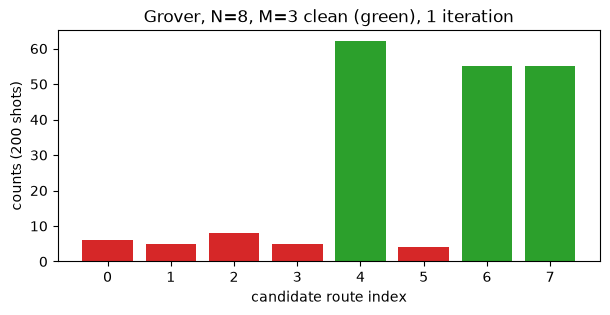

In [6]:
n = int(np.log2(N))
r = grover_iterations(N, M)
theta = np.arcsin(np.sqrt(M / N))
p_clean = np.sin((2 * r + 1) * theta) ** 2
print(f"N = {N}, M = {M}, {n} qubits, {r} iteration(s): exact chance of drawing a clean route {p_clean:.1%} "
      f"(random guessing: {M / N:.1%})")

qc = build_grover_routes(n, marked, r)
counts = sim.run(transpile(qc, sim), shots=200, memory=True).result()
shots = counts.get_memory()
by_index = Counter(int(b, 2) for b in shots)
hits = sum(by_index[i] for i in marked)
print(f"Aer, 200 shots: {hits} clean picks ({hits / 200:.0%})")

xs = list(range(N))
plt.figure(figsize=(7, 3))
plt.bar(xs, [by_index[i] for i in xs], color=["tab:green" if clean[i] else "tab:red" for i in xs])
plt.xticks(xs); plt.xlabel("candidate route index"); plt.ylabel("counts (200 shots)")
plt.title(f"Grover, N={N}, M={M} clean (green), {r} iteration"); plt.show()

**Check the pick classically.** A Grover measurement is a guess; checking it is cheap (look up each fiber's QBER). Take shots in order until one passes the check.

In [7]:
for draw, b in enumerate(shots, start=1):
    pick = int(b, 2)
    route = cands[pick]
    ok = is_clean(net, route, qber=qber)
    print(f"draw {draw}: measured {b} = route {pick}: {'clean' if ok else 'dirty, draw again'}")
    if ok:
        break
print("\nGrover's pick:", " -> ".join(label(net, x) for x in route["nodes"]), f'({route["km"]} km)')

best = find_route(net, START, END, qber=qber)
print("Dijkstra's best:", " -> ".join(label(net, x) for x in best["nodes"]), f'({best["km"]} km)')
print("Grover's pick is", "the same route." if best["links"] == route["links"] else
      "a clean route, but not the best one (finding the best is Durr-Hoyer minimum finding, a stretch goal).")

draw 1: measured 110 = route 6: clean

Grover's pick: Falling Water -> T27 -> Sequoyah -> McDonald -> Bradley -> T33 -> T26 -> Catoosa -> T6 -> JC Edwards -> Oglethorpe (88.6 km)
Dijkstra's best: Falling Water -> T27 -> Sequoyah -> McDonald -> Bradley -> T33 -> T26 -> Catoosa -> Oglethorpe (81.2 km)
Grover's pick is a clean route, but not the best one (finding the best is Durr-Hoyer minimum finding, a stretch goal).


## 5. No clean route (M = 0): fall back to ML-KEM

Now tap fiber **L61** (Falling Water – T27) as well. Every candidate starts on it, so none is clean. The oracle marks nothing, Grover's output stays uniform, and every classical check fails. That is the signal to fall back: the router finds the best route over any fiber still in service and runs it on ML-KEM keys. That route may run over the tapped fibers: a tap breaks QKD (it shows up as QBER), but it cannot read ML-KEM ciphertext, so the intermediate sites only forward it.

In [8]:
qber0 = {TAP: TAP_QBER, "L61": TAP_QBER}
marked0 = [i for i, c in enumerate(cands) if is_clean(net, c, qber=qber0)]
r0 = grover_iterations(N, len(marked0))
res0 = sim.run(transpile(build_grover_routes(n, marked0, r0), sim), shots=200).result().get_counts()
by0 = Counter({int(b, 2): c for b, c in res0.items()})
print(f"M = {len(marked0)}, {r0} iterations; counts by route index: {dict(sorted(by0.items()))}")
print("clean picks:", sum(1 for i in by0 if is_clean(net, cands[i], qber=qber0)), "of", len(by0), "distinct routes drawn")

fb = find_route(net, START, END, qber=qber0)
print(f'\nRouter fallback: mode {fb["mode"]}')
show(fb)
print("  QKD fibers blocked by the cutoff:", fb["blocked"])

M = 0, 2 iterations; counts by route index: {0: 24, 1: 32, 2: 28, 3: 23, 4: 17, 5: 27, 6: 21, 7: 28}
clean picks: 0 of 8 distinct routes drawn

Router fallback: mode pqc
  mode pqc: Falling Water -> T27 -> Sequoyah Nuclear -> T24 -> T30 -> T6 -> JC Edwards -> Oglethorpe
  70.3 km, 6 intermediate sites, highest QBER 26.8%, relays can read the key: False
  QKD fibers blocked by the cutoff: ['L14', 'L61']


## 6. What this does and does not show

- **Dijkstra solves this exactly and fast on a classical computer.** The routing problem has structure (a graph), and Grover only helps for an *unstructured* list.
- **The oracle is built from QBER values we already know classically.** Marking the clean routes required checking every route, which is already the answer. A real speed-up needs an oracle that is cheap to run in superposition but hard to invert, like the AES circuit in 2b.
- **What it does show:** the same Grover circuit from 2b (its oracle, generalised to M marks, and its diffuser, unchanged) runs on the grid problem, and it needs about √(N/M) oracle queries instead of about N/M. The quantum pick and the classical check agree, and M = 0 gives a clear fallback signal.
- **On the iteration count:** we use the optimal `floor(π / (4θ))`, not the textbook `round(π/4 · √(N/M))`, which overshoots when more than half the items are marked (and at N = 8, M = 2 it gives 2 iterations and 25% instead of 1 iteration and 100%). Both need M, which the oracle's builder knows here but a real search would not; for unknown M, the BBHT schedule (Boyer, Brassard, Høyer, Tapp 1998) uses random iteration counts with a growing limit.

This is a demonstration, not a speed-up claim.